In [1]:
!apt-get -qq install -y libarchive-tools
!mkdir -p /content/neu_raw
!bsdtar -xf /content/NEU-CLS.rar -C /content/neu_raw

from pathlib import Path
import shutil

classes = {
    "Cr": "crazing",
    "In": "inclusion",
    "Pa": "patches",
    "PS": "pitted_surface",
    "RS": "rolled_in_scale",
    "Sc": "scratches",
}
counts = {name: 0 for name in classes.values()}

for image in Path("/content/neu_raw").rglob("*.bmp"):
    code = image.stem.split("_")[0]
    folder = Path("/content/NEU") / classes[code]
    folder.mkdir(parents=True, exist_ok=True)
    shutil.copy2(image, folder / image.name)
    counts[classes[code]] += 1

print(counts)
assert all(count == 300 for count in counts.values())

Selecting previously unselected package libarchive-tools.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libarchive-tools_3.7.2-2ubuntu0.9_amd64.deb ...
Unpacking libarchive-tools (3.7.2-2ubuntu0.9) ...
Setting up libarchive-tools (3.7.2-2ubuntu0.9) ...
Processing triggers for man-db (2.12.0-4build2) ...
{'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted_surface': 300, 'rolled_in_scale': 300, 'scratches': 300}


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix,
ConfusionMatrixDisplay
)

In [3]:
torch.manual_seed(42)

In [4]:
device = torch.device(
"cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

Device: cuda


In [5]:
transform = transforms.Compose([
transforms.Grayscale(num_output_channels=1),
transforms.Resize((64, 64)),
transforms.ToTensor()
])

In [6]:
dataset = datasets.ImageFolder(
root="NEU",
transform=transform
)
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)

Number of images: 1800
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled_in_scale', 'scratches']


In [7]:
image, label = dataset[0]
print("Image shape:", image.shape)
print("Class:", dataset.classes[label])

Image shape: torch.Size([1, 64, 64])
Class: crazing


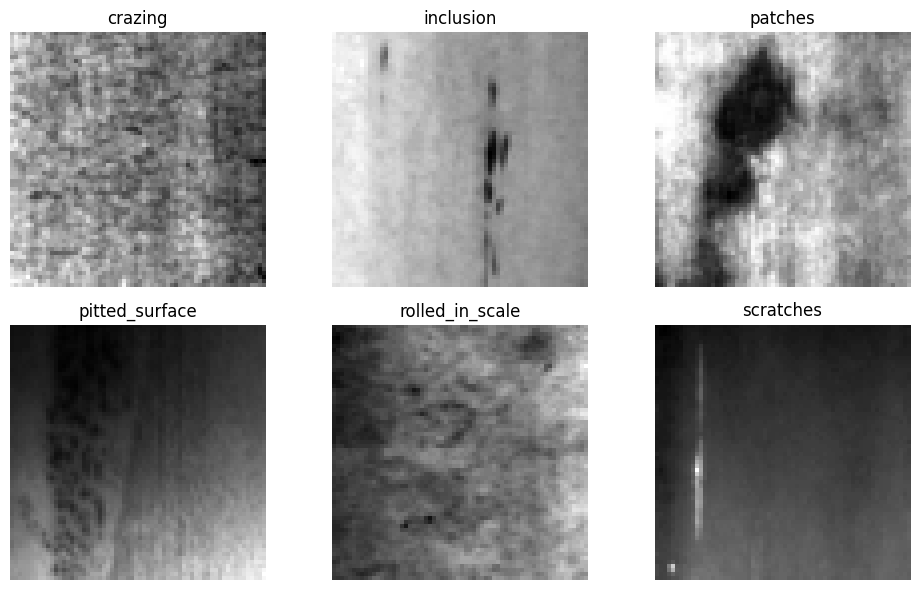

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, idx in zip(axes.flat, range(6)):
  image, label = dataset[idx * 300]
  ax.imshow(image.squeeze(), cmap="gray")
  ax.set_title(dataset.classes[label])
  ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
#Question 1: Can you visually distinguish all six defect classes easily?
#No. Rolled-in scale and crazing are not easy to spot. Also, depending on the shape, some defects are similar to others, such as small patches and big inclusions.

#Question 2: Which defect classes appear most similar?
#Patches and inclusions can be very similar with the appropriate shape.

#Question 3: Why might these similarities make classification difficult?
#These visual similarities will confuse the model to some degree because the color/texture representations of these similar defects will overlap to some extent; hence, the model may struggle to make the correct decision.

In [9]:
n = len(dataset)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val
train_set, val_set, test_set = random_split(
dataset,
[n_train, n_val, n_test],
generator=torch.Generator().manual_seed(42)
)

In [10]:
batch_size = 32
train_loader = DataLoader(
train_set,
batch_size=batch_size,
shuffle=True
)
val_loader = DataLoader(
val_set,
batch_size=batch_size,
shuffle=False
)
test_loader = DataLoader(
test_set,
batch_size=batch_size,
shuffle=False
)

In [ ]:
#Question 4: Why should the training data be shuffled?
#Training data should be shuffled to reduce any bias present in the order in which the data was collected. Since the model uses this data to train, we do not want it to pick up the wrong patterns.
#Rating: Good. Shuffling the training set prevents the model from learning spurious correlations based purely on the sequence of the classes in the dataset.

#Question 5: Why is shuffling less important for the test set?
#Shuffling is not important for the test set because the model is already trained. The model will not update its parameters as it makes predictions from the test dataset. As predictions are made independently, order will not even affect the final performance metrics.

In [11]:
class DeepNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
    nn.Flatten(),
    nn.Linear(64 * 64, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU(),
    nn.Linear(64, 6)
    )
  def forward(self, x):
    return self.network(x)
deep_model = DeepNN().to(device)
print(deep_model)

DeepNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [12]:
def count_parameters(model):
  return sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
  )
print("DNN parameters:", count_parameters(deep_model))

DNN parameters: 1065670


In [ ]:
#Question 6: Why does the first layer contain so many parameters?
#The first linear layer alone has 64x64 pixels x 256 outputs parameters plus the biases because it needs to extract the patterns from every pixel into a complex enough layer (256 outputs) to learn representational features without overfitting.

In [13]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
  deep_model.parameters(),
  lr=0.001
)

In [14]:
def train_one_epoch(model, loader, optimizer, loss_fn):
  model.train()
  total_loss = 0
  correct = 0
  total = 0
  for images, labels in loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_loss += loss.item()
    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)
  return total_loss / len(loader), correct / total

In [15]:
def evaluate(model, loader, loss_fn):
  model.eval()
  total_loss = 0
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in loader:
      images = images.to(device)
      labels = labels.to(device)
      outputs = model(images)
      loss = loss_fn(outputs, labels)
      total_loss += loss.item()
      predictions = outputs.argmax(dim=1)
      correct += (predictions == labels).sum().item()
      total += labels.size(0)
  return total_loss / len(loader), correct / total

In [16]:
epochs = 20
dnn_train_loss = []
dnn_val_loss = []
dnn_train_acc = []
dnn_val_acc = []
for epoch in range(epochs):
  train_loss, train_acc = train_one_epoch(
    deep_model, train_loader, optimizer, loss_fn
  )
  val_loss, val_acc = evaluate(
    deep_model, val_loader, loss_fn
  )
  dnn_train_loss.append(train_loss)
  dnn_val_loss.append(val_loss)
  dnn_train_acc.append(train_acc)
  dnn_val_acc.append(val_acc)
  print(
    f"Epoch {epoch+1:02d} | "
    f"Train Acc: {train_acc:.3f} | "
    f"Val Acc: {val_acc:.3f}"
  )

Epoch 01 | Train Acc: 0.166 | Val Acc: 0.237
Epoch 02 | Train Acc: 0.224 | Val Acc: 0.215
Epoch 03 | Train Acc: 0.248 | Val Acc: 0.263
Epoch 04 | Train Acc: 0.271 | Val Acc: 0.337
Epoch 05 | Train Acc: 0.343 | Val Acc: 0.281
Epoch 06 | Train Acc: 0.338 | Val Acc: 0.370
Epoch 07 | Train Acc: 0.361 | Val Acc: 0.396
Epoch 08 | Train Acc: 0.357 | Val Acc: 0.359
Epoch 09 | Train Acc: 0.385 | Val Acc: 0.404
Epoch 10 | Train Acc: 0.436 | Val Acc: 0.452
Epoch 11 | Train Acc: 0.440 | Val Acc: 0.459
Epoch 12 | Train Acc: 0.483 | Val Acc: 0.400
Epoch 13 | Train Acc: 0.475 | Val Acc: 0.519
Epoch 14 | Train Acc: 0.511 | Val Acc: 0.448
Epoch 15 | Train Acc: 0.515 | Val Acc: 0.456
Epoch 16 | Train Acc: 0.540 | Val Acc: 0.478
Epoch 17 | Train Acc: 0.548 | Val Acc: 0.526
Epoch 18 | Train Acc: 0.565 | Val Acc: 0.507
Epoch 19 | Train Acc: 0.543 | Val Acc: 0.548
Epoch 20 | Train Acc: 0.544 | Val Acc: 0.467


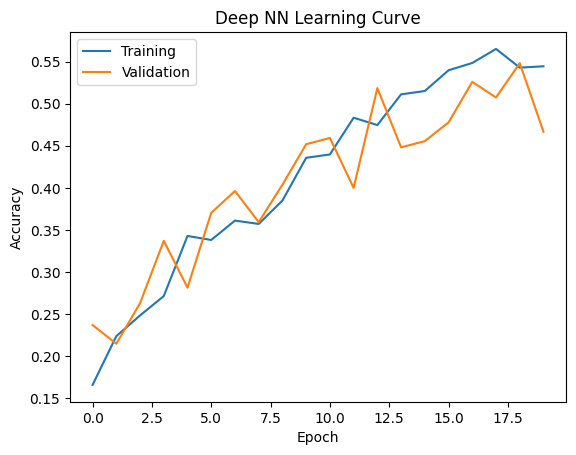

In [17]:
plt.plot(dnn_train_acc, label="Training")
plt.plot(dnn_val_acc, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep NN Learning Curve")
plt.legend()
plt.show()

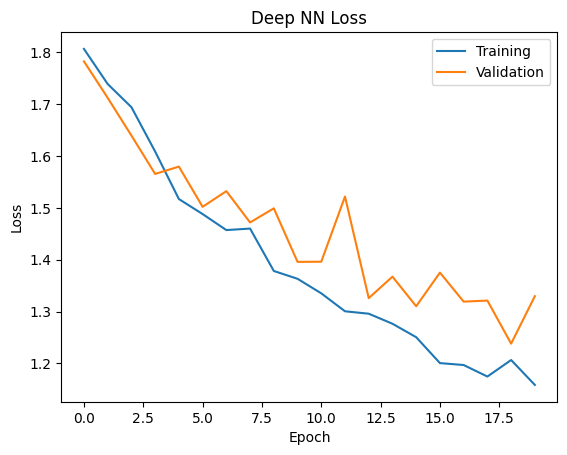

In [18]:
plt.plot(dnn_train_loss, label="Training")
plt.plot(dnn_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep NN Loss")
plt.legend()
plt.show()

In [ ]:
#Question 7: Does the model appear to be learning?
#Yes. Both training and validation loss are following a decreasing tendency after each epoch.

#Question 8: Is there evidence of overfitting?
#No. Validation loss follows training loss closely, which means there is no overfitting after 20 epochs.

#Question 9: At approximately which epoch does validation performance stop improving?
#After epoch 40, there is barely any improvement.

In [19]:
nn.MaxPool2d(2)

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [20]:
class CNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
      nn.Conv2d(1, 16, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(16, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2)
    )
    self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(64 * 8 * 8, 128),
      nn.ReLU(),
      nn.Linear(128, 6)
    )
  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

In [21]:
cnn_model = CNN().to(device)
print(cnn_model)
print("CNN parameters:", count_parameters(cnn_model))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)
CNN parameters: 548486


In [22]:
import pandas as pd

Model = [
    {'label': 'Deep NN', 'Parameters': 1065670},
    {'label': 'CNN', 'Parameters': 548486},
]
df = pd.DataFrame(Model)
df.columns = ['Model', 'Parameters']
df

,Model,Parameters
0,Deep NN,1065670
1,CNN,548486


In [ ]:
#Question 10: Which model has more trainable parameters?
#The deep neural network has nearly twice as many parameters as the CNN.

#Question 11: Why can a CNN process an image effectively without connecting every input pixel to every hidden neuron?
#Since the CNN passes a small filter across the image, it can detect relationships among pixels (such as edges or depth) that a DNN cannot easily do using only dense layers.

In [23]:
cnn_optimizer = torch.optim.Adam(
  cnn_model.parameters(),
  lr=0.001
)
cnn_train_loss = []
cnn_val_loss = []
cnn_train_acc = []
cnn_val_acc = []
for epoch in range(epochs):
  train_loss, train_acc = train_one_epoch(
    cnn_model, train_loader, cnn_optimizer, loss_fn
  )
  val_loss, val_acc = evaluate(
    cnn_model, val_loader, loss_fn
  )
  cnn_train_loss.append(train_loss)
  cnn_val_loss.append(val_loss)
  cnn_train_acc.append(train_acc)
  cnn_val_acc.append(val_acc)
  print(
    f"Epoch {epoch+1:02d} | "
    f"Train Acc: {train_acc:.3f} | "
    f"Val Acc: {val_acc:.3f}"
  )

Epoch 01 | Train Acc: 0.298 | Val Acc: 0.378
Epoch 02 | Train Acc: 0.456 | Val Acc: 0.511
Epoch 03 | Train Acc: 0.602 | Val Acc: 0.519
Epoch 04 | Train Acc: 0.634 | Val Acc: 0.607
Epoch 05 | Train Acc: 0.697 | Val Acc: 0.678
Epoch 06 | Train Acc: 0.758 | Val Acc: 0.719
Epoch 07 | Train Acc: 0.785 | Val Acc: 0.756
Epoch 08 | Train Acc: 0.813 | Val Acc: 0.833
Epoch 09 | Train Acc: 0.851 | Val Acc: 0.837
Epoch 10 | Train Acc: 0.829 | Val Acc: 0.778
Epoch 11 | Train Acc: 0.868 | Val Acc: 0.826
Epoch 12 | Train Acc: 0.878 | Val Acc: 0.815
Epoch 13 | Train Acc: 0.879 | Val Acc: 0.852
Epoch 14 | Train Acc: 0.915 | Val Acc: 0.900
Epoch 15 | Train Acc: 0.924 | Val Acc: 0.896
Epoch 16 | Train Acc: 0.928 | Val Acc: 0.904
Epoch 17 | Train Acc: 0.916 | Val Acc: 0.893
Epoch 18 | Train Acc: 0.933 | Val Acc: 0.859
Epoch 19 | Train Acc: 0.933 | Val Acc: 0.859
Epoch 20 | Train Acc: 0.948 | Val Acc: 0.915


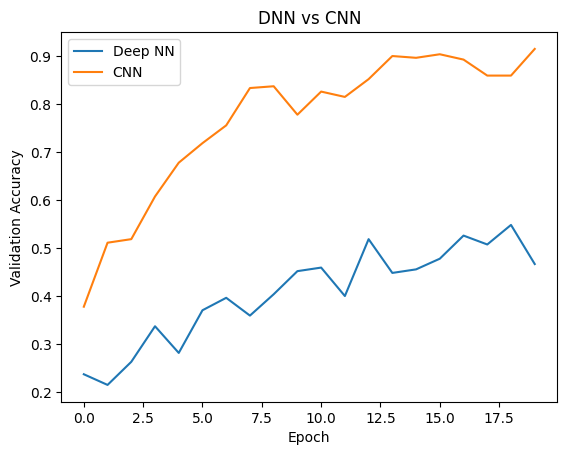

In [24]:
plt.plot(dnn_val_acc, label="Deep NN")
plt.plot(cnn_val_acc, label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("DNN vs CNN")
plt.legend()
plt.show()

In [ ]:
#Question 12: Which model learns faster?
#The CNN learns much faster than the DNN.

#Question 13: Which achieves better validation performance?
#The CNN's validation performance outperforms the DNN by more than 0.3 in accuracy after 20 epochs.

#Question 14: Which appears more stable during training?
#The CNN appears to be much more stable.

In [25]:
dnn_test_loss, dnn_test_acc = evaluate(
  deep_model, test_loader, loss_fn
)
cnn_test_loss, cnn_test_acc = evaluate(
  cnn_model, test_loader, loss_fn
)
print("DNN Test Accuracy:", dnn_test_acc)
print("CNN Test Accuracy:", cnn_test_acc)

DNN Test Accuracy: 0.48518518518518516
CNN Test Accuracy: 0.9185185185185185


In [26]:
import pandas as pd

Model = [
    {'label': 'Deep NN', 'Test Accuracy': 0.485185},
    {'label': 'CNN', 'Test Accuracy': 0.918518},
]
df = pd.DataFrame(Model)
df.columns = ['Model', 'Test Accuracy']
df['Test Accuracy'] = df['Test Accuracy'].round(4)
df

,Model,Test Accuracy
0,Deep NN,0.4852
1,CNN,0.9185


In [27]:
all_labels = []
all_predictions = []
cnn_model.eval()
with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    outputs = cnn_model(images)
    predictions = outputs.argmax(dim=1)
    all_labels.extend(labels.numpy())
    all_predictions.extend(predictions.cpu().numpy())

In [28]:
print(
  classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes,
    digits=3
  )
)

                 precision    recall  f1-score   support

        crazing      0.960     0.941     0.950        51
      inclusion      0.814     0.854     0.833        41
        patches      1.000     0.976     0.988        42
 pitted_surface      0.885     0.885     0.885        52
rolled_in_scale      0.932     1.000     0.965        41
      scratches      0.925     0.860     0.892        43

       accuracy                          0.919       270
      macro avg      0.919     0.919     0.919       270
   weighted avg      0.920     0.919     0.919       270



In [ ]:
#Question 15: Which class has the highest recall?
#patches with 0.976

#Question 16: Which class has the lowest recall?
#inclusion with 0.854

#Question 17: Why might recall be particularly important in an industrial defect-detection system?
#In an industrial setting, recall is important because it represents the hability of the model to catch that defect. A false negative means shipping a damaged steel sheet to a customer, which may lead to structural failure. A false positive simply leads to double-checking a non-defective sheet, which is far less important than missing an actual defect.

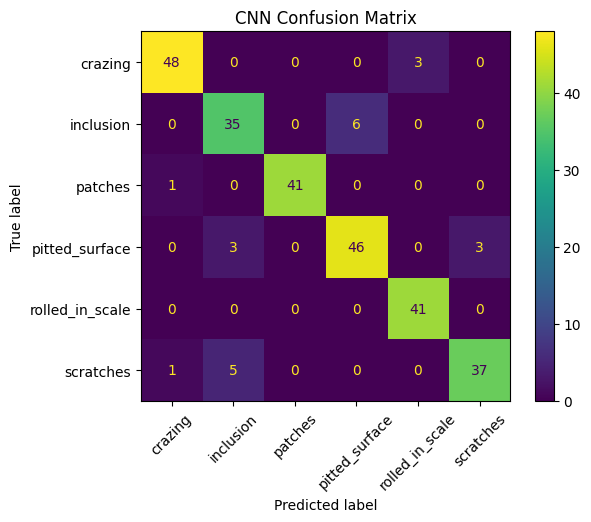

In [29]:
cm = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(
  confusion_matrix=cm,
  display_labels=dataset.classes
)
display.plot(xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.show()

In [ ]:
#Question 18: Which two defect types are most frequently confused?
#Inclusion are most frequently confused with pitted_surface.

#Question 19: Can you find a possible visual or mechanical explanation?
#Inclusions and pitted surfaces both appear as localized, dark, and high-contrast irregular shapes in a 64x64 grayscale image. The lack of different elongation or directional patterns make the CNN confuses their feature representations.

In [30]:
cnn_model.eval()
mistakes = []
with torch.no_grad():
  for images, labels in test_loader:
    outputs = cnn_model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()
    for image, true, pred in zip(images, labels, predictions):
      if true != pred:
        mistakes.append((image, true, pred))

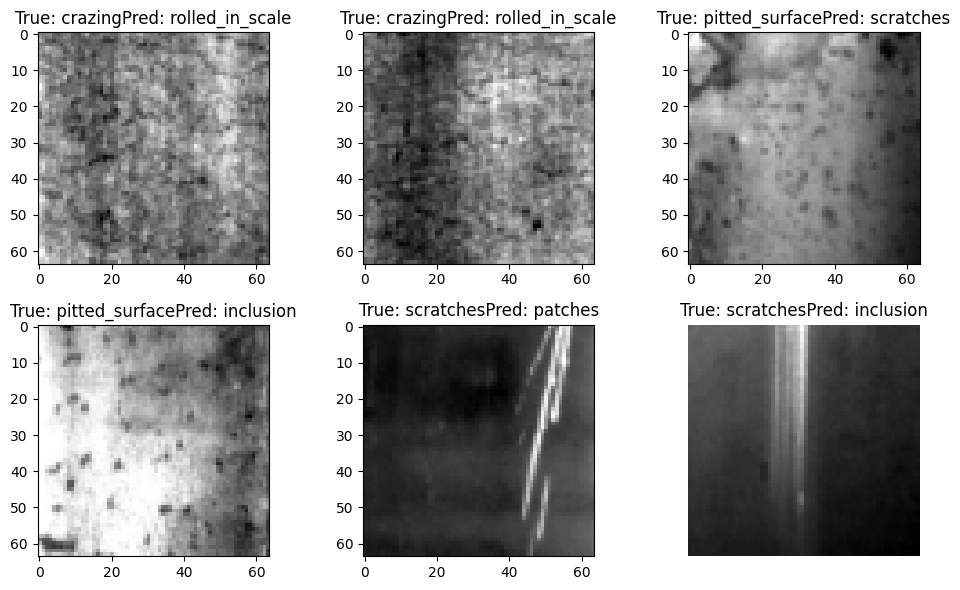

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, item in zip(axes.flat, mistakes[:6]):
  image, true, pred = item
  ax.imshow(image.squeeze(), cmap="gray")
  ax.set_title(
    f"True: {dataset.classes[true]}"
    f"Pred: {dataset.classes[pred]}"
  )
ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# For the first image, the model predicted it to be rolled_in_scale, yet it was actually crazing. The image really looks like crazing to me, so I would be surprised if the model had predicted it correctly. Since rolled_in_scale tends to be more serious than crazing, this particular mistake is not critical in a manufacturing context.

In [ ]:
# For the third image, the model predicted it to be scratches, yet it was actually a pitted_surface. In this case, the image does not looks like a scratch, I would understand if the model predicted it as an inclusion or even patches, but not this. This type of error could be prevented with a bit more training. Furthermore, since scratches tend to be more serious than a pitted_surface, this mistake is not highly critical for manufacturing safety.

In [ ]:
# For the fourth image, the model predicted it to be an inclusion, yet it was actually a pitted_surface. Similar to the first error, this image is difficult to predict because this specific pitted surface strongly resembles an inclusion. Because an inclusion is generally much more serious than a pitted surface, over-classifying it is a safe error and would not be considered a critical failure in manufacturing.

In [ ]:
#Question 20: Are the errors random, or do certain classes appear repeatedly?
#No, the errors are not entirely random. Certain classes stand out significantly: such as inclusion which has the lowest recall and precision. This class repeatedly account for a large portion of the model's mistakes.

In [32]:
import pandas as pd

Model = [
    {'Characteristic': 'Input representation', 'Deep NN':  'Flattened pixels', 'CNN': '2D image'},
    {'Characteristic': 'Uses spatial relationships', 'Deep NN': 'Limited ', 'CNN': 'Yes'},
    {'Characteristic': 'Local feature extraction', 'Deep NN': 'No ', 'CNN': 'Yes'},
    {'Characteristic': 'Weight sharing', 'Deep NN': 'No ', 'CNN': 'Yes'},
    {'Characteristic': 'Test accuracy', 'Deep NN': 0.4852, 'CNN': 0.9185},
    {'Characteristic': 'Parameter count', 'Deep NN': 1065670, 'CNN': 548486
},
]
df = pd.DataFrame(Model)
df.columns = ['Characteristic', 'Deep NN', 'CNN']
df

,Characteristic,Deep NN,CNN
0,Input representation,Flattened pixels,2D image
1,Uses spatial relationships,Limited,Yes
2,Local feature extraction,No,Yes
3,Weight sharing,No,Yes
4,Test accuracy,0.4852,0.9185
5,Parameter count,1065670,548486


In [33]:
!pip install -q gradio
import gradio as gr

In [34]:
from PIL import Image
def predict_defect(image):
  image = transform(image)
  image = image.unsqueeze(0)
  image = image.to(device)
  cnn_model.eval()
  with torch.no_grad():
    outputs = cnn_model(image)
    probabilities = torch.softmax(outputs, dim=1)[0]
  results = {}
  for class_name, probability in zip(
    dataset.classes,
    probabilities.cpu().numpy()
  ):
    results[class_name] = float(probability)
  return results

In [35]:
app = gr.Interface(
  fn=predict_defect,
  inputs=gr.Image(type="pil"),
  outputs=gr.Label(num_top_classes=6),
  title="Steel Surface Defect Classifier",
  description=(
    "Upload an image of a steel surface and "
    "the CNN will predict the defect type."
  )
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://467727ac7ad544866b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [48]:
import pandas as pd

Model = [
    {'Image': 'classified correctly', 'True Class':  'patches', 'Predicted Class': 'patches', 'Confidence': '100.00%'},
    {'Image': 'classified incorrectly', 'True Class': 'inclusion', 'Predicted Class': 'pitted_surface', 'Confidence': '93.49%'},
    {'Image': 'ambiguous-looking', 'True Class': 'scratches', 'Predicted Class': 'crazing', 'Confidence': '45.50%'},
]
df = pd.DataFrame(Model)
df.columns = ['Image', 'True Class', 'Predicted Class', 'Confidence']
df

,Image,True Class,Predicted Class,Confidence
0,classified correctly,patches,patches,100.00%
1,classified incorrectly,inclusion,pitted_surface,93.49%
2,ambiguous-looking,scratches,crazing,45.50%


In [ ]:
#Question 21: Find one example where the model gives substantial confidence to an incorrect prediction.

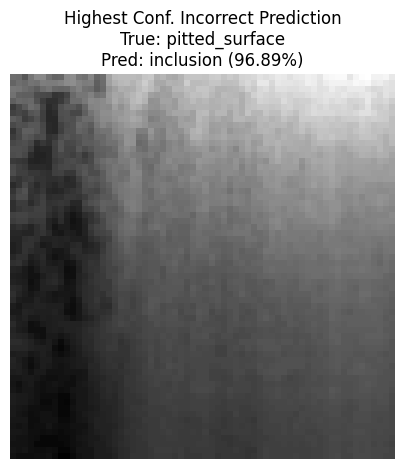

Saved to: /content/highest_confidence_incorrect.png


In [45]:
import torch
import matplotlib.pyplot as plt

# Ensure model is in evaluation mode
cnn_model.eval()

highest_bad_conf = 0.0
highest_bad_img = None
highest_bad_true = None
highest_bad_pred = None

# Map indices to label names
class_names = dataset.classes

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        outputs = cnn_model(images_dev)
        probs = torch.softmax(outputs, dim=1).cpu()

        for img, true_label, prob_dist in zip(images, labels, probs):
            pred_label = torch.argmax(prob_dist).item()
            conf = prob_dist[pred_label].item()
            true_val = true_label.item()

            if pred_label != true_val and conf > highest_bad_conf:
                highest_bad_conf = conf
                highest_bad_img = img
                highest_bad_true = true_val
                highest_bad_pred = pred_label

if highest_bad_img is not None:
    img_np = highest_bad_img.squeeze().numpy()

    plt.imsave("/content/highest_confidence_incorrect.png", img_np, cmap='gray')

    plt.figure(figsize=(5, 5))
    plt.imshow(img_np, cmap='gray')
    plt.title(f"Highest Conf. Incorrect Prediction\nTrue: {class_names[highest_bad_true]}\nPred: {class_names[highest_bad_pred]} ({highest_bad_conf:.2%})")
    plt.axis('off')
    plt.show()

    print(f"Saved to: /content/highest_confidence_incorrect.png")

In [49]:
#Question 22: Would you allow this classifier to automatically reject expensive manufactured components without human review? Explain.
#It would depend on the economic trade-offs within the company. Specifically, would the cost of hiring human reviewers be less than the expected financial losses resulting from incorrect automated model rejections?

In [ ]:
#Increasing the number of epochs from 20 to 40 will definetly improve the model accuracy. Overfitting risk exist but would still be low.

In [60]:
cnn_model = CNN().to(device)
cnn_optimizer = torch.optim.Adam(
  cnn_model.parameters(),
  lr=0.001
)
cnn_train_loss = []
cnn_val_loss = []
cnn_train_acc = []
cnn_val_acc = []
epochss=40
for epoch in range(epochss):
  train_loss, train_acc = train_one_epoch(
    cnn_model, train_loader, cnn_optimizer, loss_fn
  )
  val_loss, val_acc = evaluate(
    cnn_model, val_loader, loss_fn
  )
  cnn_train_loss.append(train_loss)
  cnn_val_loss.append(val_loss)
  cnn_train_acc.append(train_acc)
  cnn_val_acc.append(val_acc)
  print(
    f"Epoch {epoch+1:02d} | "
    f"Train Acc: {train_acc:.3f} | "
    f"Val Acc: {val_acc:.3f}"
  )

Epoch 01 | Train Acc: 0.306 | Val Acc: 0.544
Epoch 02 | Train Acc: 0.529 | Val Acc: 0.411
Epoch 03 | Train Acc: 0.593 | Val Acc: 0.604
Epoch 04 | Train Acc: 0.672 | Val Acc: 0.656
Epoch 05 | Train Acc: 0.730 | Val Acc: 0.689
Epoch 06 | Train Acc: 0.752 | Val Acc: 0.752
Epoch 07 | Train Acc: 0.819 | Val Acc: 0.767
Epoch 08 | Train Acc: 0.842 | Val Acc: 0.830
Epoch 09 | Train Acc: 0.874 | Val Acc: 0.848
Epoch 10 | Train Acc: 0.887 | Val Acc: 0.870
Epoch 11 | Train Acc: 0.902 | Val Acc: 0.874
Epoch 12 | Train Acc: 0.907 | Val Acc: 0.885
Epoch 13 | Train Acc: 0.919 | Val Acc: 0.889
Epoch 14 | Train Acc: 0.907 | Val Acc: 0.881
Epoch 15 | Train Acc: 0.920 | Val Acc: 0.881
Epoch 16 | Train Acc: 0.936 | Val Acc: 0.922
Epoch 17 | Train Acc: 0.946 | Val Acc: 0.922
Epoch 18 | Train Acc: 0.947 | Val Acc: 0.889
Epoch 19 | Train Acc: 0.949 | Val Acc: 0.911
Epoch 20 | Train Acc: 0.925 | Val Acc: 0.930
Epoch 21 | Train Acc: 0.946 | Val Acc: 0.926
Epoch 22 | Train Acc: 0.966 | Val Acc: 0.915
Epoch 23 |

In [61]:
cnn_test_loss, cnn_test_acc = evaluate(
  cnn_model, test_loader, loss_fn
)
print("CNN Test Accuracy:", cnn_test_acc)
print("CNN parameters:", count_parameters(cnn_model))

CNN Test Accuracy: 0.9407407407407408
CNN parameters: 548486


In [65]:
import pandas as pd

Model = [
    {'Model': 'Original CNN', 'Validation Accuracy':  0.915, 'Test Accuracy': 0.919, 'Parameters': 548486},
    {'Model': 'Modified CNN', 'Validation Accuracy': 0.952, 'Test Accuracy': 0.941, 'Parameters': 548486},
]
df = pd.DataFrame(Model)
df.columns = ['Model', 'Validation Accuracy', 'Test Accuracy', 'Parameters']
df

,Model,Validation Accuracy,Test Accuracy,Parameters
0,Original CNN,0.915,0.919,548486
1,Modified CNN,0.952,0.941,548486


In [ ]:
#Question 23: Did the result support your hypothesis?
#They did. The modified CNN performed slightly better without increasing the number of parameters

#Question 24: Did the more complicated model necessarily perform better?
#It did in this case. But more complicated model may lead to overfitting or gradient vanishing.

In [70]:
#R1: Why is a fully connected neural network not naturally suited to image data?
#Fully connected networks flatten 2D image spatial structures into 1D vectors, losing spatial relationw between neighboring pixels, such as edges and depth. Additionally, because every input pixel connects to every neuron, they suffer from a massive parameter explosion which leads to overfitting and high computational costs.

#R2: What is the advantage of applying the same convolutional filter at many image locations?
#It reduces the total number of parameters. It also grants the model translation invariance, meaning it can detect features no matter where they appears in the image.

#R3: What does pooling accomplish?
#Pooling reduces the spatial dimensions of, in this case, images. This reduces computational complexity, lowers the risk of overfitting by abstracting features, and give some translation and scale invariance.

#R4: Why should test data not be repeatedly used while modifying the CNN?
#Repeatedly using the test set to tune the model leaks information from the test set into the design process. The test dataset would be, to some extent, doing the fuction of the trainin dataset, so it would lose it purpose.

#R5: Why is a confusion matrix more informative than accuracy alone for this problem?
#Accuracy can hide poor performance on specific classes, especially if the dataset is unbalanced. A confusion matrix reveals exactly which defect classes are being misclassified as others, allowing us to see if critical defects are being missed or mislabeled.

#R6: Which failure would be more serious in an industrial setting: incorrectly rejecting a good component or accepting a defective component? Does the answer always remain the same?
#Accepting a defective component is generally far more serious. An incorrected rejected component would only cause financial losses while accepting a defective component can lead to future infraestrutural failero, safety hazard and other serious non monetary risks

#R7: What additional evidence would you require before deploying this classifier on an actual production line?
#I would ask for more large test dataset to see the performance of the model as well as demo of at least one week in the production line since the contrast and iluminations of the images will be different the data provided.